<a href="https://colab.research.google.com/github/grapefruitstack/CoffeeShopPrediction2025/blob/main/Finalized_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Imports and Data

# ========= LOGICAL REGRESSION SECTION =========


In [ ]:
# @title
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

# Load dataset
df = pd.read_csv("/content/Coffee_Sales_Cleaned.csv")

# Ensure Date is datetime and sort by it
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(by='Date')

# Quick preview
df.head()

,hour_of_day,cash_type,money,coffee_name,Time_of_Day,Weekday,Month_name,Weekdaysort,Monthsort,Date,Time
0,10,card,38.7,Latte,Morning,Fri,Mar,5,3,2024-03-01,15:50.5
9,19,card,33.8,Americano with Milk,Night,Fri,Mar,5,3,2024-03-01,23:15.9
8,19,card,38.7,Cocoa,Night,Fri,Mar,5,3,2024-03-01,22:01.8
7,18,card,33.8,Americano with Milk,Night,Fri,Mar,5,3,2024-03-01,39:03.6
6,16,card,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3,2024-03-01,19:02.8


## Data Split 60/20/20

In [ ]:
# @title
train_list, val_list, test_list = [], [], []

for month, month_df in df.groupby('Monthsort'):
    month_df = month_df.sort_values('Date')
    n = len(month_df)
    if n < 5:  # skip months with very few rows
        continue

    train_end = int(0.6 * n)
    val_end = int(0.8 * n)

    train_list.append(month_df.iloc[:train_end])
    val_list.append(month_df.iloc[train_end:val_end])
    test_list.append(month_df.iloc[val_end:])

# Combine splits
train_df = pd.concat(train_list)
val_df = pd.concat(val_list)
test_df = pd.concat(test_list)

print(f"Training size: {len(train_df)}, Validation size: {len(val_df)}, Test size: {len(test_df)}")


Training size: 1931, Validation size: 646, Test size: 651


## Categorical Variables

In [ ]:
# @title

categorical_cols = ['Time_of_Day', 'Weekdaysort']

train_encoded = pd.get_dummies(train_df, columns=categorical_cols, drop_first=True)
val_encoded = pd.get_dummies(val_df, columns=categorical_cols, drop_first=True)
test_encoded = pd.get_dummies(test_df, columns=categorical_cols, drop_first=True)

# Align columns (ensures all sets have same features)
train_encoded, val_encoded = train_encoded.align(val_encoded, join='left', axis=1, fill_value=0)
train_encoded, test_encoded = train_encoded.align(test_encoded, join='left', axis=1, fill_value=0)

print("Encoded feature count:", train_encoded.shape[1])


Encoded feature count: 17


## Define Features and Target

In [ ]:
# @title
# === Cell 4: Define X (features) and y (target) ===

# Target: which coffee is ordered
y_train = train_encoded['coffee_name']
y_val = val_encoded['coffee_name']
y_test = test_encoded['coffee_name']

# Features: remove target + non-predictive columns
drop_cols = ['Date', 'money', 'Weekday', 'Month_name', 'cash_type', 'time_of_day']
X_train = train_encoded.drop(columns=drop_cols, errors='ignore')
X_val = val_encoded.drop(columns=drop_cols, errors='ignore')
X_test = test_encoded.drop(columns=drop_cols, errors='ignore')

X_train.head()


,hour_of_day,coffee_name,Monthsort,Time,Time_of_Day_Morning,Time_of_Day_Night,Weekdaysort_2,Weekdaysort_3,Weekdaysort_4,Weekdaysort_5,Weekdaysort_6,Weekdaysort_7
2612,17,Cappuccino,1,43:10.2,False,True,False,False,True,False,False,False
2611,16,Americano with Milk,1,35:44.3,False,False,False,False,True,False,False,False
2610,16,Hot Chocolate,1,34:59.5,False,False,False,False,True,False,False,False
2608,14,Cortado,1,42:45.8,False,False,False,False,True,False,False,False
2609,16,Americano,1,22:32.4,False,False,False,False,True,False,False,False


## Standardize Features

In [ ]:
# @title
for df_split in [X_train, X_val, X_test]:
    if 'cash_type' in df_split.columns:
        df_split.drop(columns=['cash_type'], inplace=True)

# Select only numeric columns for scaling
numeric_cols = X_train.select_dtypes(include=[np.number]).columns

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train[numeric_cols])
X_val_scaled = scaler.transform(X_val[numeric_cols])
X_test_scaled = scaler.transform(X_test[numeric_cols])


## Logisitic Regression

In [ ]:
# @title
log_reg = LogisticRegression(max_iter=1000)

log_reg.fit(X_train_scaled, y_train)

val_score = log_reg.score(X_val_scaled, y_val)
test_score = log_reg.score(X_test_scaled, y_test)

print("Validation Accuracy:", round(val_score, 3))
print("Test Accuracy:", round(test_score, 3))


Validation Accuracy: 0.251
Test Accuracy: 0.243


## Cross-Validation for Logistic Regression

In [ ]:
# @title
cv_scores = cross_val_score(log_reg, X_train_scaled, y_train, cv=5)
print("Cross-validation Accuracy Scores:", cv_scores)
print("Mean CV Accuracy:", round(cv_scores.mean(), 3))


Cross-validation Accuracy Scores: [0.14470284 0.23834197 0.25906736 0.23834197 0.22020725]
Mean CV Accuracy: 0.22


## Linear Regression

In [ ]:
# @title
# === Cell 8: Linear Regression Baseline ===
from sklearn.linear_model import LinearRegression

# Encode coffee_name as integers for regression
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_train_lr = le.fit_transform(y_train)
y_val_lr = le.transform(y_val)
y_test_lr = le.transform(y_test)

# Fit linear regression
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train_lr)

# Evaluate
val_score_lr = lin_reg.score(X_val_scaled, y_val_lr)
test_score_lr = lin_reg.score(X_test_scaled, y_test_lr)

print("Linear Regression Validation R²:", round(val_score_lr, 3))
print("Linear Regression Test R²:", round(test_score_lr, 3))


Linear Regression Validation R²: 0.043
Linear Regression Test R²: 0.011


## Cross-Validation for Linear Regression

In [ ]:
# @title
# === Cell 9: Linear Regression Cross-Validation ===
from sklearn.model_selection import cross_val_score

# 5-fold cross-validation on training set
cv_scores_lr = cross_val_score(lin_reg, X_train_scaled, y_train_lr, cv=5)
print("Linear Regression CV Scores:", np.round(cv_scores_lr, 3))
print("Mean CV R²:", round(cv_scores_lr.mean(), 3))

Linear Regression CV Scores: [ 0.027 -0.001  0.01  -0.02   0.008]
Mean CV R²: 0.005


## Performance Metrics

Validation Set Classification Report:

                     precision    recall  f1-score   support

          Americano       0.17      0.01      0.02        94
Americano with Milk       0.25      0.65      0.36       147
         Cappuccino       0.00      0.00      0.00        92
              Cocoa       0.00      0.00      0.00        44
            Cortado       0.00      0.00      0.00        63
           Espresso       0.00      0.00      0.00        25
      Hot Chocolate       0.00      0.00      0.00        47
              Latte       0.26      0.49      0.34       134

           accuracy                           0.25       646
          macro avg       0.08      0.14      0.09       646
       weighted avg       0.13      0.25      0.16       646


Test Set Classification Report:

                     precision    recall  f1-score   support

          Americano       0.33      0.01      0.02        87
Americano with Milk       0.23      0.62      0.34       158
        

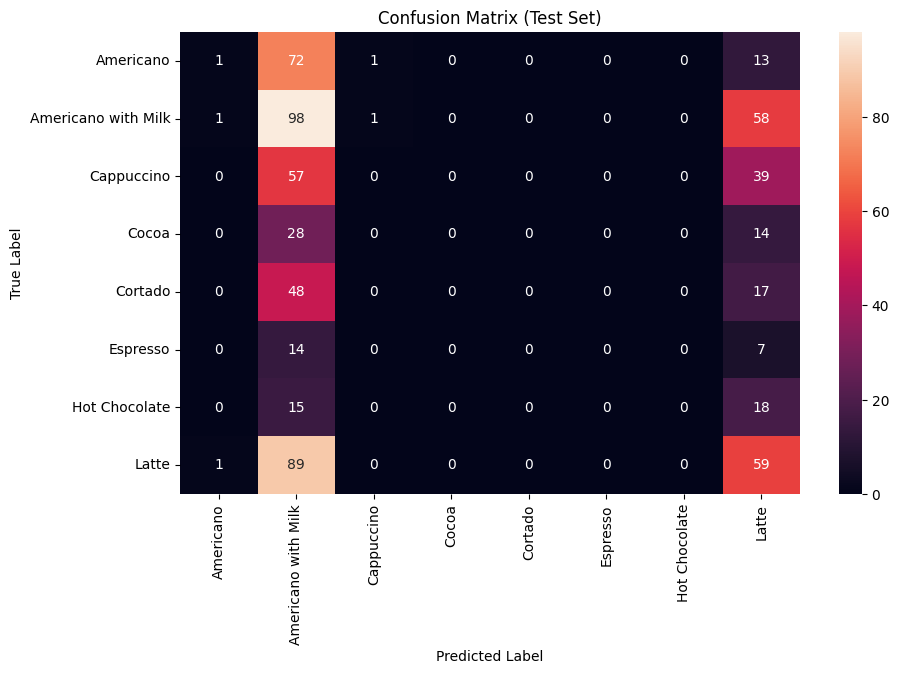

In [ ]:
# @title
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_pred_val = log_reg.predict(X_val_scaled)
y_pred_test = log_reg.predict(X_test_scaled)

print("Validation Set Classification Report:\n")
print(classification_report(y_val, y_pred_val, zero_division=0))
print("\nTest Set Classification Report:\n")
print(classification_report(y_test, y_pred_test, zero_division=0))

plt.figure(figsize=(10, 6))
cm = confusion_matrix(y_test, y_pred_test, labels=log_reg.classes_)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=log_reg.classes_, yticklabels=log_reg.classes_)
plt.title("Confusion Matrix (Test Set)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

## Statistical significance testing for model coefficients

In [ ]:
# @title
X_train_const = sm.add_constant(X_train_scaled)
model_sm = sm.MNLogit(y_train.astype('category').cat.codes, X_train_const)
result = model_sm.fit(method='newton', maxiter=100, disp=False)

print(result.summary())


                          MNLogit Regression Results                          
Dep. Variable:                      y   No. Observations:                 1931
Model:                        MNLogit   Df Residuals:                     1910
Method:                           MLE   Df Model:                           14
Date:                Fri, 19 Dec 2025   Pseudo R-squ.:                 0.02118
Time:                        04:40:39   Log-Likelihood:                -3663.2
converged:                       True   LL-Null:                       -3742.5
Covariance Type:            nonrobust   LLR p-value:                 1.403e-26
       y=1       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.5229      0.079      6.617      0.000       0.368       0.678
x1             0.1160      0.080      1.441      0.149      -0.042       0.274
x2             0.2160      0.076      2.843      0.0

In [ ]:
# @title

print("Mapping of numerical codes to coffee names:")
for code, name in zip(le.transform(le.classes_), le.classes_):
    print(f"y={code}: {name}")

print("\nNumeric columns used for scaling (corresponding to x1, x2, etc.):")
print(numeric_cols.tolist())

Mapping of numerical codes to coffee names:
y=0: Americano
y=1: Americano with Milk
y=2: Cappuccino
y=3: Cocoa
y=4: Cortado
y=5: Espresso
y=6: Hot Chocolate
y=7: Latte

Numeric columns used for scaling (corresponding to x1, x2, etc.):
['hour_of_day', 'Monthsort']


## Accuracy Confidence Intervals + Cross-Validation

In [ ]:
# @title
n_bootstraps = 500
boot_scores = []

rng = np.random.default_rng(42)
for _ in range(n_bootstraps):
    indices = rng.choice(len(X_test_scaled), len(X_test_scaled), replace=True)
    boot_acc = (y_test.iloc[indices].reset_index(drop=True) == log_reg.predict(X_test_scaled[indices])).mean()
    boot_scores.append(boot_acc)

conf_int = np.percentile(boot_scores, [2.5, 97.5])
print(f"95% Confidence Interval for Test Accuracy: [{conf_int[0]:.3f}, {conf_int[1]:.3f}]")

cv_scores = cross_val_score(log_reg, X_train_scaled, y_train, cv=5, scoring='accuracy')
print("CV Scores:", np.round(cv_scores, 3))
print("Mean CV Accuracy:", round(cv_scores.mean(), 3))
print("Standard Deviation:", round(cv_scores.std(), 3))



95% Confidence Interval for Test Accuracy: [0.209, 0.276]
CV Scores: [0.145 0.238 0.259 0.238 0.22 ]
Mean CV Accuracy: 0.22
Standard Deviation: 0.04


# =================== DECISION TREE SECTION ===================

In [ ]:
# @title
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

print(df.head())


   hour_of_day cash_type  money          coffee_name Time_of_Day Weekday  \
0           10      card   38.7                Latte     Morning     Fri   
9           19      card   33.8  Americano with Milk       Night     Fri   
8           19      card   38.7                Cocoa       Night     Fri   
7           18      card   33.8  Americano with Milk       Night     Fri   
6           16      card   38.7        Hot Chocolate   Afternoon     Fri   

  Month_name  Weekdaysort  Monthsort       Date     Time  
0        Mar            5          3 2024-03-01  15:50.5  
9        Mar            5          3 2024-03-01  23:15.9  
8        Mar            5          3 2024-03-01  22:01.8  
7        Mar            5          3 2024-03-01  39:03.6  
6        Mar            5          3 2024-03-01  19:02.8  


## Decision Tree Time of Day Difference Variables

In [ ]:
# @title
def add_daily_variation_features(data):
    # Count drinks per day per time of day
    day_time_counts = (
        data.groupby(['Date', 'Time_of_Day', 'coffee_name'])
        .size()
        .reset_index(name='count')
    )

    # Pivot so columns = morning, afternoon, night
    pivoted = day_time_counts.pivot_table(
        index=['Date', 'coffee_name'],
        columns='Time_of_Day',
        values='count',
        fill_value=0
    ).reset_index()

    # Rename pivoted columns
    pivoted = pivoted.rename(columns={
        'Morning': 'Count_Morn',
        'Afternoon': 'Count_Aft',
        'Night': 'Count_Night'
    })

    # Create differences
    pivoted['Diff_Morn_Aft']  = pivoted['Count_Morn'] - pivoted['Count_Aft']
    pivoted['Diff_Aft_Night'] = pivoted['Count_Aft']  - pivoted['Count_Night']
    pivoted['Diff_Morn_Night'] = pivoted['Count_Morn'] - pivoted['Count_Night']

    # Merge back into dataset
    return data.merge(pivoted[['Date','coffee_name','Diff_Morn_Aft','Diff_Aft_Night','Diff_Morn_Night']],
                      on=['Date','coffee_name'],
                      how='left')


## Decision Tree Feature Selection / Split

In [ ]:
# Drop unwanted columns
df = df.drop(columns=["Date", "cash_type", "money", 'Time_of_Day'], errors="ignore") # Exclude 'money'

# Encode categorical features
categorical_cols = ["coffee_name", "Weekdaysort"]

le_dict = {}

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    le_dict[col] = le

# Define features (X) and target (y) based on user's request
X = df[["Weekdaysort", "Monthsort", "hour_of_day"]]
y = df["coffee_name"]

# Train/Val/Test Split (same sizes you mentioned)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=42, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print("Training size:", len(X_train))
print("Validation size:", len(X_val))
print("Test size:", len(X_test))


Training size: 1936
Validation size: 646
Test size: 646


## Decision Tree Model Training

In [ ]:
# @title
baseline_tree = DecisionTreeClassifier(random_state=42)
baseline_tree.fit(X_train, y_train)

y_val_pred = baseline_tree.predict(X_val)

print("Baseline Accuracy:", accuracy_score(y_val, y_val_pred))
print("Baseline F1 (macro):", f1_score(y_val, y_val_pred, average="macro"))


Baseline Accuracy: 0.23374613003095976
Baseline F1 (macro): 0.1861467433894582


## Decision Tree Feature Importance

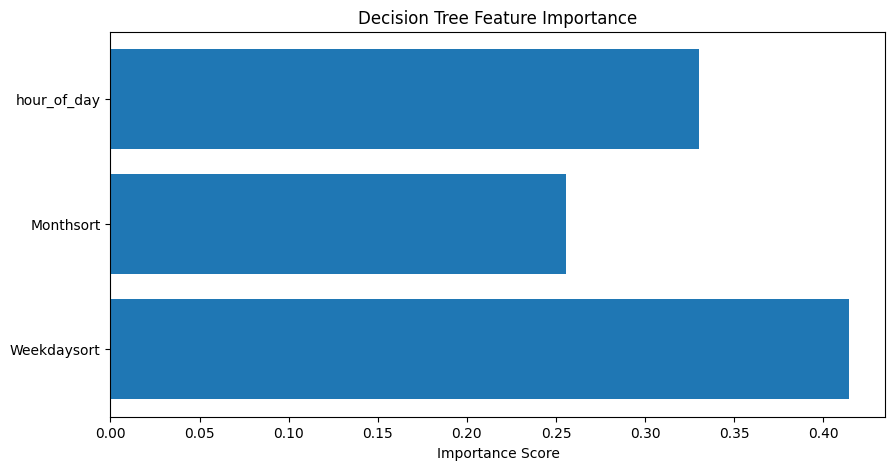

In [ ]:
# @title
import pandas as pd
import matplotlib.pyplot as plt

importances = baseline_tree.feature_importances_
feat_names = X_train.columns

plt.figure(figsize=(10,5))
plt.barh(feat_names, importances)
plt.xlabel("Importance Score")
plt.title("Decision Tree Feature Importance")
plt.show()


## Decision Tree Confusion Matrix

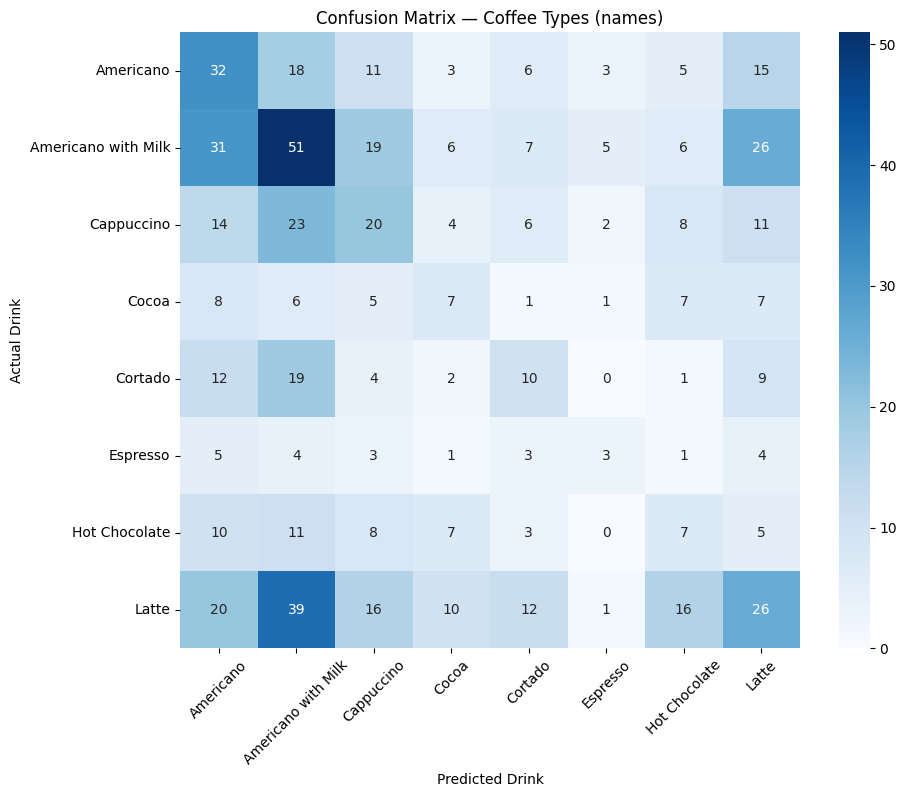

In [ ]:
# @title
labels = log_reg.classes_  # Use the Logistic Regression classes for consistent naming


y_pred_num = baseline_tree.predict(X_test)
y_test_num = y_test.values if hasattr(y_test, "values") else np.array(y_test)

# Map numerical labels to their string names using 'labels' for display
y_pred_names = np.array([labels[int(i)] for i in y_pred_num])
y_test_names = np.array([labels[int(i)] for i in y_test_num])

from sklearn.metrics import confusion_matrix
# For confusion_matrix, the `labels` parameter should correspond to the unique
# values in y_true and y_pred.
cm = confusion_matrix(y_test_names, y_pred_names, labels=labels)

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels) # Changed cmap to 'Blues'
plt.xlabel("Predicted Drink")
plt.ylabel("Actual Drink")
plt.title("Confusion Matrix — Coffee Types (names)")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

# Decision Tree

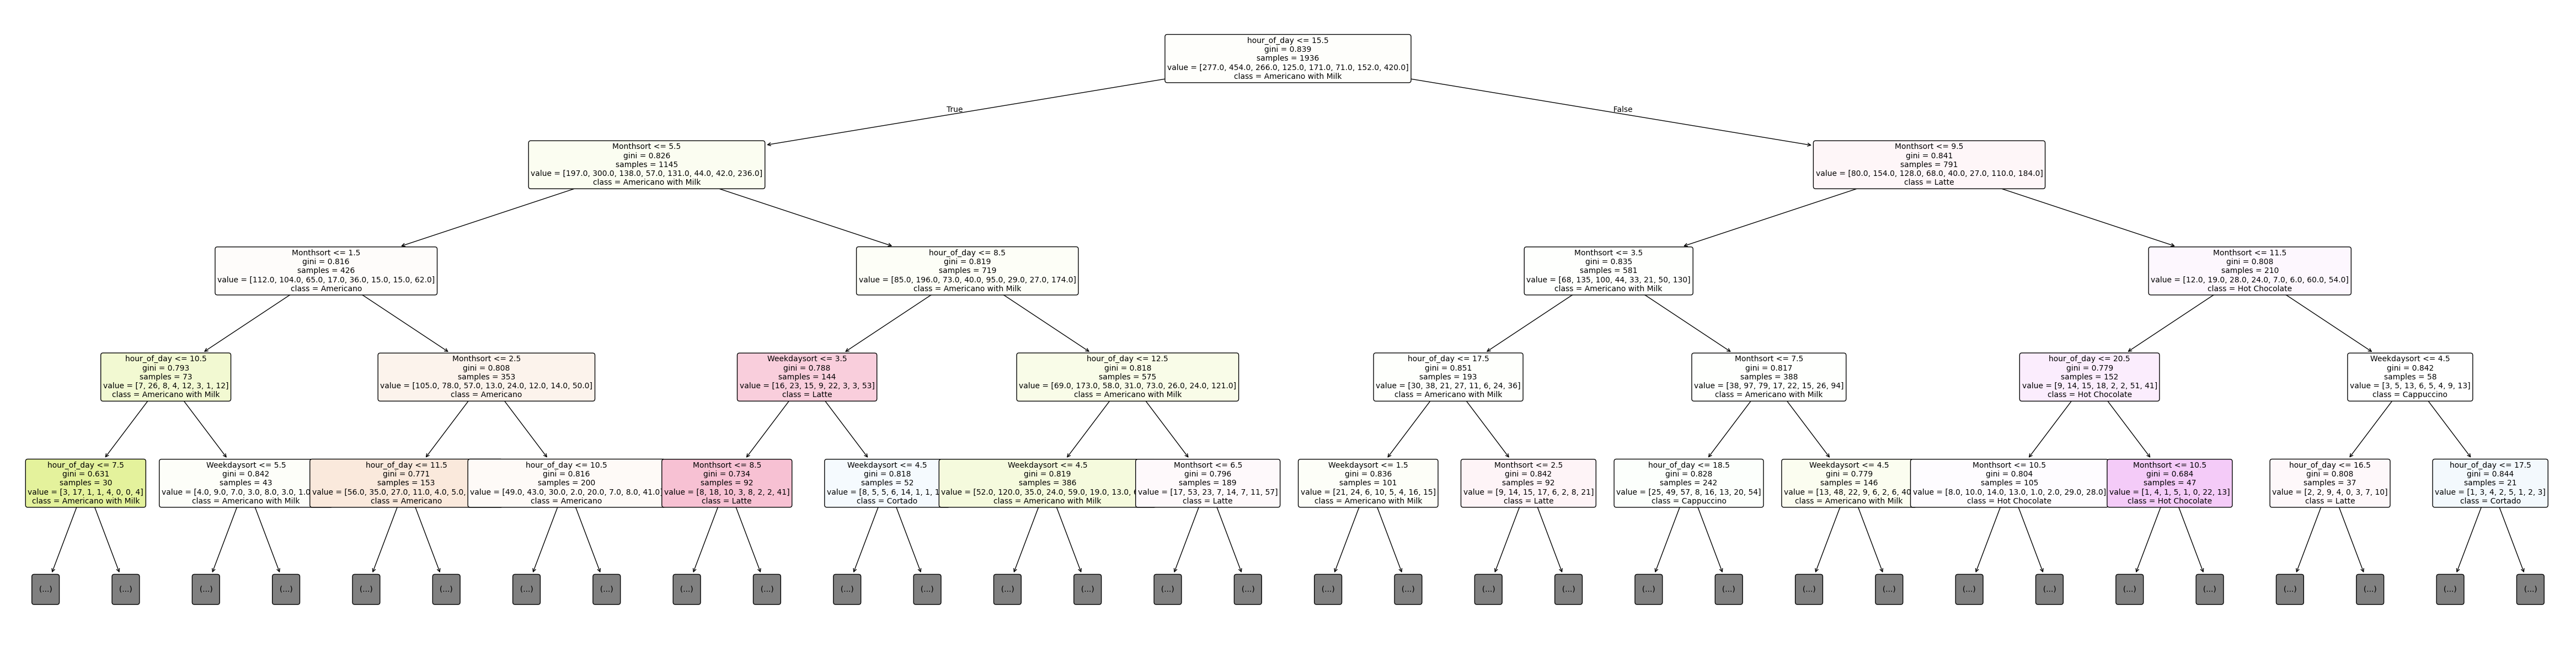

In [ ]:
# @title
from sklearn import tree
import matplotlib.pyplot as plt

plt.figure(figsize=(60, 15)) # Increased the width from 30 to 40
tree.plot_tree(
    baseline_tree,
    feature_names=X_train.columns,
    class_names=labels,   # Use the 'labels' variable from the previous cell
    filled=True,
    rounded=True,
    fontsize=10,
    max_depth=4  # Limit the depth to make it more readable
)
plt.show()


# ========= WITH THE DIFFERENCES VARIABLE ADDED =========

## Decision Tree Feature Selection / Split w/ Variables

In [ ]:
# @title
# Apply the add_daily_variation_features function to the already split dataframes
train_df_dt = add_daily_variation_features(train_df.copy())
val_df_dt = add_daily_variation_features(val_df.copy())
test_df_dt = add_daily_variation_features(test_df.copy())

# Define categorical columns for Label Encoding in the Decision Tree section
categorical_cols_dt = ['coffee_name', 'Weekdaysort']

le_dict_dt = {}

# Iterate and apply LabelEncoder to each split DataFrame
for col in categorical_cols_dt:
    le = LabelEncoder()
    train_df_dt[col] = le.fit_transform(train_df_dt[col])
    # Use the same encoder fitted on train_df_dt to transform validation and test sets
    val_df_dt[col] = le.transform(val_df_dt[col])
    test_df_dt[col] = le.transform(test_df_dt[col])
    le_dict_dt[col] = le

# Define target variables
y_train = train_df_dt['coffee_name']
y_val = val_df_dt['coffee_name']
y_test = test_df_dt['coffee_name']

# Define columns to drop from the feature sets
drop_cols_from_X_dt = [
    'Date', 'cash_type', 'money', 'Weekday', 'Month_name', 'Time', 'coffee_name', 'Time_of_Day'
]

# Define feature sets (X)
X_train = train_df_dt.drop(columns=drop_cols_from_X_dt, errors='ignore')
X_val = val_df_dt.drop(columns=drop_cols_from_X_dt, errors='ignore')
X_test = test_df_dt.drop(columns=drop_cols_from_X_dt, errors='ignore')

print(f"Training size: {len(X_train)}")
print(f"Validation size: {len(X_val)}")
print(f"Test size: {len(X_test)}")

Training size: 1931
Validation size: 646
Test size: 651


## Decision Tree Model Training w/ Variables

In [ ]:
# @title
baseline_tree = DecisionTreeClassifier(random_state=42)
baseline_tree.fit(X_train, y_train)

y_val_pred = baseline_tree.predict(X_val)

print("Baseline Accuracy:", accuracy_score(y_val, y_val_pred))
print("Baseline F1 (macro):", f1_score(y_val, y_val_pred, average="macro"))

Baseline Accuracy: 0.1826625386996904
Baseline F1 (macro): 0.14218901357756294


## Decision Tree Feature Importance w/ Variables

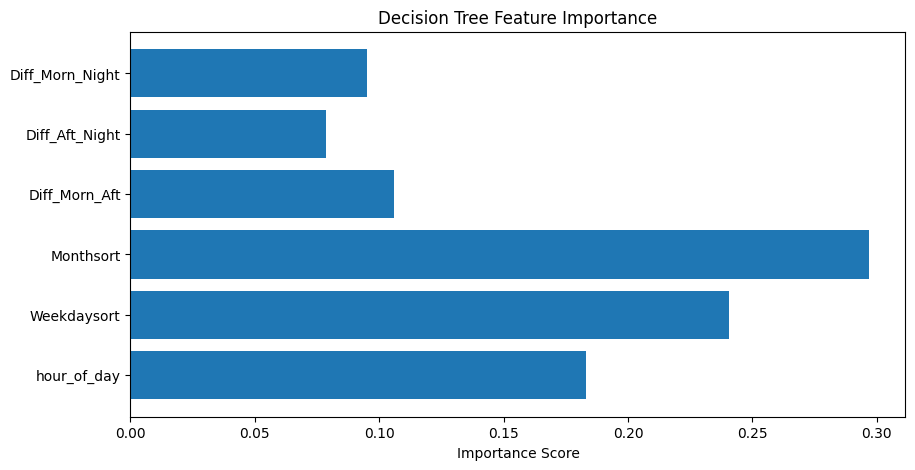

In [ ]:
# @title
importances = baseline_tree.feature_importances_
feat_names = X_train.columns

plt.figure(figsize=(10,5))
plt.barh(feat_names, importances)
plt.xlabel("Importance Score")
plt.title("Decision Tree Feature Importance")
plt.show()

## Decision Tree Confusion Matrix w/ Variables

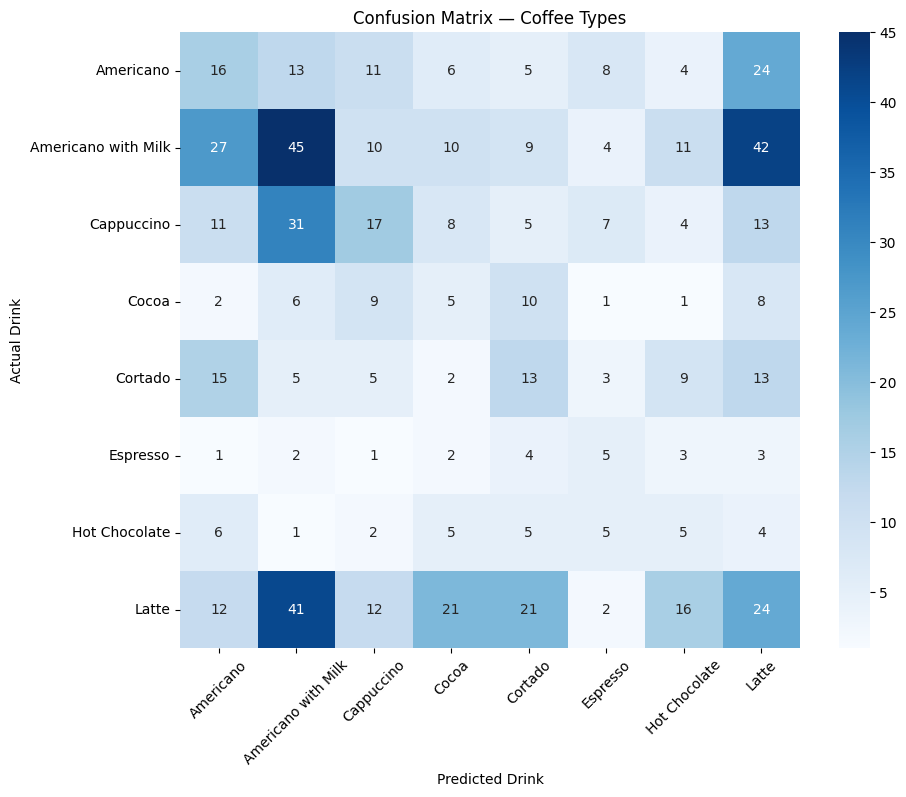

In [ ]:
# @title
labels = log_reg.classes_  # Use the Logistic Regression classes for consistent naming


y_pred_num = baseline_tree.predict(X_test)
y_test_num = y_test.values if hasattr(y_test, "values") else np.array(y_test)

# Map numerical labels to their string names using 'labels' for display
y_pred_names = np.array([labels[int(i)] for i in y_pred_num])
y_test_names = np.array([labels[int(i)] for i in y_test_num])

from sklearn.metrics import confusion_matrix
# For confusion_matrix, the `labels` parameter should correspond to the unique
# values in y_true and y_pred.
cm = confusion_matrix(y_test_names, y_pred_names, labels=labels)

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels) # Changed cmap to 'Blues'
plt.xlabel("Predicted Drink")
plt.ylabel("Actual Drink")
plt.title("Confusion Matrix — Coffee Types")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

# ================== SINGLE MONTH TESTING ====================


## Single Month March Testing

In [ ]:
# @title
df_march = df[df['Monthsort'] == 3]
print(f"Original DataFrame size: {len(df)}")
print(f"March DataFrame size: {len(df_march)}")
df_march.head()

Original DataFrame size: 3228
March DataFrame size: 175


,hour_of_day,coffee_name,Weekday,Month_name,Weekdaysort,Monthsort,Time
0,10,7,Fri,Mar,4,3,15:50.5
9,19,1,Fri,Mar,4,3,23:15.9
8,19,3,Fri,Mar,4,3,22:01.8
7,18,1,Fri,Mar,4,3,39:03.6
6,16,6,Fri,Mar,4,3,19:02.8


In [ ]:
# @title
df_march = df_march.copy()

# Define features (X) and target (y)
# According to the task, features are 'Monthsort', 'Weekdaysort', 'hour_of_day'
# And the target is 'coffee_name'
X = df_march[['Monthsort', 'Weekdaysort', 'hour_of_day']]
y = df_march['coffee_name']

print("Features (X) head:\n", X.head())
print("\nTarget (y) head:\n", y.head())

Features (X) head:
    Monthsort  Weekdaysort  hour_of_day
0          3            4           10
9          3            4           19
8          3            4           19
7          3            4           18
6          3            4           16

Target (y) head:
 0    7
9    1
8    3
7    1
6    6
Name: coffee_name, dtype: int64


## March Month Split

In [ ]:
# @title
from sklearn.model_selection import train_test_split

# Split into training (60%) and temporary (40%) sets
X_train_march, X_temp_march, y_train_march, y_temp_march = train_test_split(
    X, y, test_size=0.40, random_state=42, stratify=y
)

# Split temporary (40%) into validation (20%) and test (20%) sets
X_val_march, X_test_march, y_val_march, y_test_march = train_test_split(
    X_temp_march, y_temp_march, test_size=0.50, random_state=42, stratify=y_temp_march
)

print(f"Training set size: {len(X_train_march)}")
print(f"Validation set size: {len(X_val_march)}")
print(f"Test set size: {len(X_test_march)}")

Training set size: 105
Validation set size: 35
Test set size: 35


## March Month Training

In [ ]:
# @title
from sklearn.metrics import accuracy_score, f1_score
from sklearn.tree import DecisionTreeClassifier

baseline_tree_march = DecisionTreeClassifier(random_state=42)
baseline_tree_march.fit(X_train_march, y_train_march)

y_val_pred_march = baseline_tree_march.predict(X_val_march)

accuracy_march = accuracy_score(y_val_march, y_val_pred_march)
f1_macro_march = f1_score(y_val_march, y_val_pred_march, average='macro', zero_division=0)

print(f"Validation Accuracy for March data: {accuracy_march:.3f}")
print(f"Validation F1-score (macro) for March data: {f1_macro_march:.3f}")

Validation Accuracy for March data: 0.286
Validation F1-score (macro) for March data: 0.230


## March Month Confusion Matrix

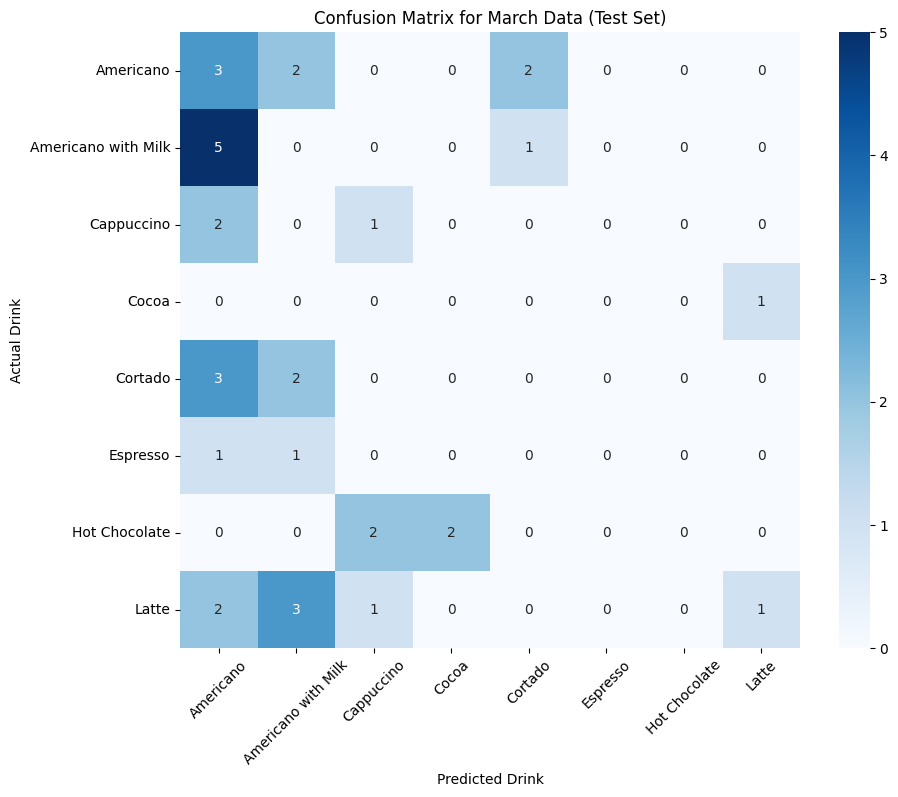

In [ ]:
# @title
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_pred_test_march = baseline_tree_march.predict(X_test_march)
y_test_march_array = y_test_march.values if hasattr(y_test_march, "values") else np.array(y_test_march)
cm_march = confusion_matrix(y_test_march_array, y_pred_test_march, labels=le_dict['coffee_name'].transform(le_dict['coffee_name'].classes_))

plt.figure(figsize=(10, 8))
sns.heatmap(cm_march, annot=True, fmt='d', cmap='Blues',
            xticklabels=le_dict['coffee_name'].classes_,
            yticklabels=le_dict['coffee_name'].classes_)
plt.xlabel("Predicted Drink")
plt.ylabel("Actual Drink")
plt.title("Confusion Matrix for March Data (Test Set)")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

## March Month Important Features

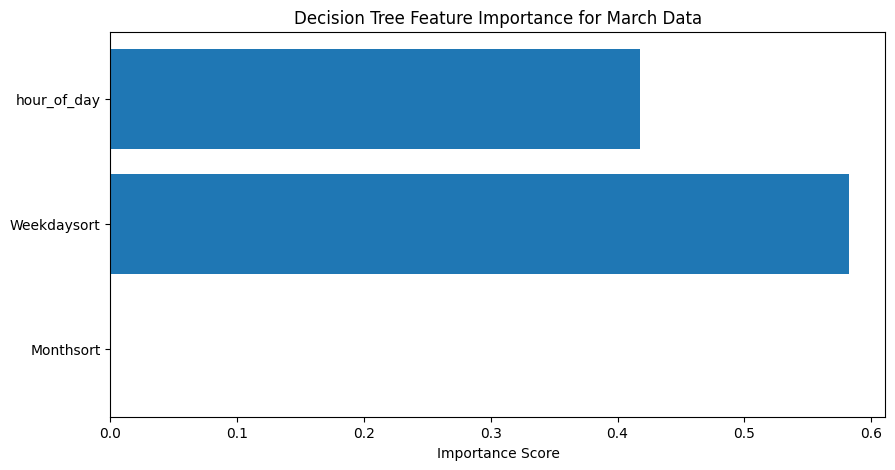

In [ ]:
# @title
importances_march = baseline_tree_march.feature_importances_
feat_names_march = X_train_march.columns

plt.figure(figsize=(10,5))
plt.barh(feat_names_march, importances_march)
plt.xlabel("Importance Score")
plt.title("Decision Tree Feature Importance for March Data")
plt.show()

## DECEMBER

In [ ]:
# @title
df_december = df[df['Monthsort'] == 12]
print(f"Original DataFrame size: {len(df)}")
print(f"December DataFrame size: {len(df_december)}")
df_december.head()

Original DataFrame size: 3228
December DataFrame size: 259


,hour_of_day,coffee_name,Weekday,Month_name,Weekdaysort,Monthsort,Time
2353,15,7,Sun,Dec,6,12,57:49.4
2358,18,1,Sun,Dec,6,12,38:28.7
2357,17,1,Sun,Dec,6,12,11:32.0
2356,17,1,Sun,Dec,6,12,10:23.6
2355,16,7,Sun,Dec,6,12,34:30.0


In [ ]:
# @title
df_december = df_december.copy()

X = df_december[['Monthsort', 'Weekdaysort', 'hour_of_day']]
y = df_december['coffee_name']

print("Features (X) head:\n", X.head())
print("\nTarget (y) head:\n", y.head())

Features (X) head:
       Monthsort  Weekdaysort  hour_of_day
2353         12            6           15
2358         12            6           18
2357         12            6           17
2356         12            6           17
2355         12            6           16

Target (y) head:
 2353    7
2358    1
2357    1
2356    1
2355    7
Name: coffee_name, dtype: int64


## December Month Split

In [ ]:
# @title
from sklearn.model_selection import train_test_split

X_train_december, X_temp_december, y_train_december, y_temp_december = train_test_split(
    X, y, test_size=0.40, random_state=42, stratify=y
)

X_val_december, X_test_december, y_val_december, y_test_december = train_test_split(
    X_temp_december, y_temp_december, test_size=0.50, random_state=42, stratify=y_temp_december
)

print(f"Training set size: {len(X_train_december)}")
print(f"Validation set size: {len(X_val_december)}")
print(f"Test set size: {len(X_test_december)}")

Training set size: 155
Validation set size: 52
Test set size: 52


## December Month Training

In [ ]:
# @title
from sklearn.metrics import accuracy_score, f1_score
from sklearn.tree import DecisionTreeClassifier

baseline_tree_december = DecisionTreeClassifier(random_state=42)
baseline_tree_december.fit(X_train_december, y_train_december)

y_val_pred_december = baseline_tree_december.predict(X_val_december)

accuracy_december = accuracy_score(y_val_december, y_val_pred_december)
f1_macro_december = f1_score(y_val_december, y_val_pred_december, average='macro', zero_division=0)

print(f"Validation Accuracy for December data: {accuracy_december:.3f}")
print(f"Validation F1-score (macro) for December data: {f1_macro_december:.3f}")

Validation Accuracy for December data: 0.154
Validation F1-score (macro) for December data: 0.090


## December Month Confusion Matrix

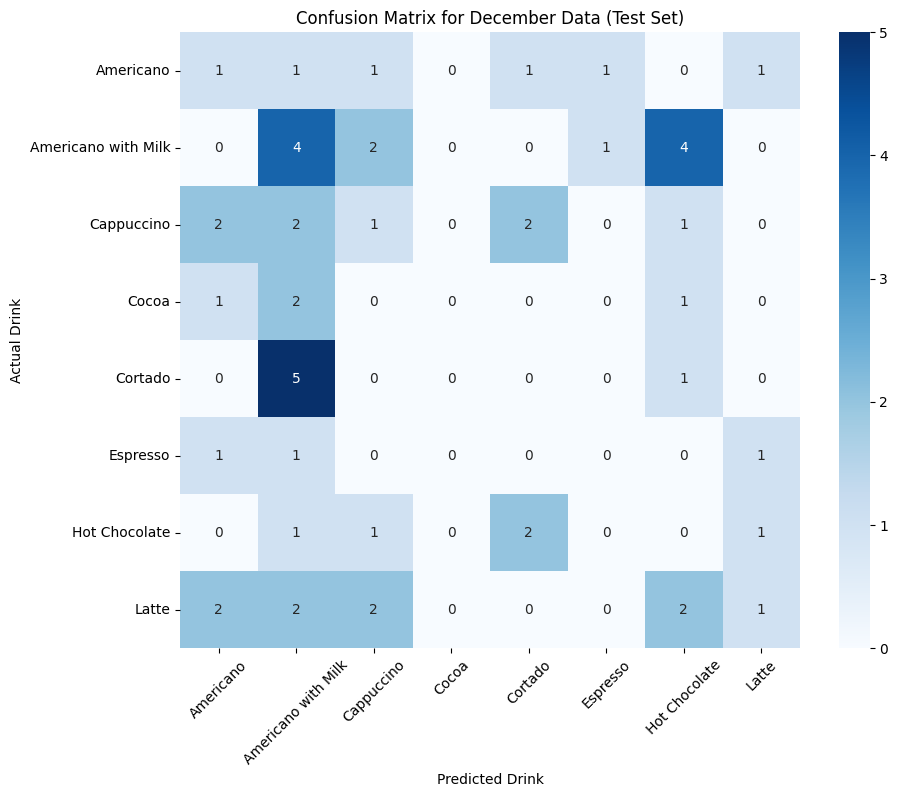

In [ ]:
# @title
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_pred_test_december = baseline_tree_december.predict(X_test_december)

y_test_december_array = y_test_december.values if hasattr(y_test_december, "values") else np.array(y_test_december)


class_names_december = le_dict['coffee_name'].classes_

cm_december = confusion_matrix(y_test_december_array, y_pred_test_december, labels=le_dict['coffee_name'].transform(class_names_december))

plt.figure(figsize=(10, 8))
sns.heatmap(cm_december, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names_december,
            yticklabels=class_names_december)
plt.xlabel("Predicted Drink")
plt.ylabel("Actual Drink")
plt.title("Confusion Matrix for December Data (Test Set)")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

## December Month Feature Importance

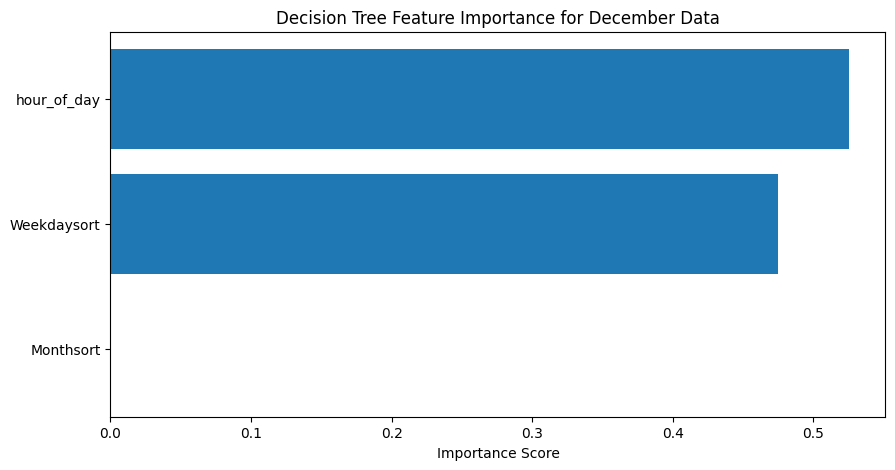

In [ ]:
# @title
importances_december = baseline_tree_december.feature_importances_
feat_names_december = X_train_december.columns

plt.figure(figsize=(10,5))
plt.barh(feat_names_december, importances_december)
plt.xlabel("Importance Score")
plt.title("Decision Tree Feature Importance for December Data")
plt.show()